# Preprocesado de datasets en Python: guía de uso de las funciones

**Autor:** Hugo González González

## Introducción

Este notebook muestra cómo usar las funciones del paquete `datasethgg` (versión en Python del paquete de R del mismo nombre). Las implementaciones de discretización, entropía, información mutua, curva ROC y AUC son propias: solo se usan `numpy`, `pandas` (estructuras de datos y funciones básicas como `cut`/`qcut`) y `plotnine` para los gráficos.

Como datos de ejemplo usamos `iris`, añadiendo una variable categórica (`tamano`) y una clase binaria (`virginica`, que vale `"si"` si la flor es de esa especie).

## 0. Preparación

Importamos el paquete con `from datasethgg import *`, de modo que todas las funciones se llaman directamente por su nombre. Para el ejemplo también necesitamos `numpy`, `pandas` y `scikit-learn` (solo para cargar `iris`).

In [3]:
import copy
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from plotnine import theme_light, theme_minimal

from datasethgg import *

In [4]:
iris = load_iris(as_frame=True)
especie = iris.target_names[iris.target]

df = pd.DataFrame({
    "sepal_length": iris.data["sepal length (cm)"],
    "sepal_width":  iris.data["sepal width (cm)"],
    "petal_length": iris.data["petal length (cm)"],
    "petal_width":  iris.data["petal width (cm)"],
    "especie":      especie,
    "tamano":       np.where(iris.data["sepal length (cm)"] < 5.8, "pequena", "grande"),
    "virginica":    np.where(especie == "virginica", "si", "no"),
})
df.head()

,sepal_length,sepal_width,petal_length,petal_width,especie,tamano,virginica
0,5.1,3.5,1.4,0.2,setosa,pequena,no
1,4.9,3.0,1.4,0.2,setosa,pequena,no
2,4.7,3.2,1.3,0.2,setosa,pequena,no
3,4.6,3.1,1.5,0.2,setosa,pequena,no
4,5.0,3.6,1.4,0.2,setosa,pequena,no


## 1. Objetos: atributos y dataset

Hay dos tipos de atributo, `NumericAttribute` y `CategoricalAttribute`, y un `Dataset` formado por una colección de atributos más, opcionalmente, el nombre de la variable clase. Se crea con `from_dataframe()` a partir de un `DataFrame`:

In [5]:
ds = from_dataframe(df, class_name="virginica")
ds

Dataset: 7 variables
Clase: virginica
 - sepal_length: numeric
 - sepal_width: numeric
 - petal_length: numeric
 - petal_width: numeric
 - especie: categorical
 - tamano: categorical
 - virginica: categorical

Se puede acceder a cada atributo a través de `ds.attributes`:

In [6]:
print(ds.attributes["petal_length"])
print(ds.attributes["petal_length"].values[:5])
print(ds.class_name)

<NumericAttribute 'petal_length' n=150>
[1.4 1.4 1.3 1.5 1.4]
virginica


El propio objeto comprueba que sea válido (por ejemplo, que la clase sea categórica):

In [7]:
try:
    from_dataframe(df, class_name="sepal_length")
except ValueError as e:
    print("ValueError:", e)

ValueError: La clase debe ser categorica


Para volver a un `DataFrame` se usa `to_dataframe()`:

In [8]:
to_dataframe(ds).head(3)

,sepal_length,sepal_width,petal_length,petal_width,especie,tamano,virginica
0,5.1,3.5,1.4,0.2,setosa,pequena,no
1,4.9,3.0,1.4,0.2,setosa,pequena,no
2,4.7,3.2,1.3,0.2,setosa,pequena,no


## 2. Discretización

Hay dos algoritmos: igual anchura (`discretizeEW`) e igual frecuencia (`discretizeEF`). Devuelven el vector discretizado (con los intervalos como categorías) y los puntos de corte.

In [9]:
x = [11.5, 10.2, 1.2, 0.5, 5.3, 20.5, 8.4]

x_ew, cut_ew = discretizeEW(x, 4)
print(x_ew)
print("Puntos de corte:", cut_ew)

[(10.5, 15.5], (5.5, 10.5], (0.499, 5.5], (0.499, 5.5], (0.499, 5.5], (15.5, 20.5], (5.5, 10.5]]
Categories (4, interval[float64, right]): [(0.499, 5.5] < (5.5, 10.5] < (10.5, 15.5] < (15.5, 20.5]]
Puntos de corte: [ 0.5  5.5 10.5 15.5 20.5]


In [10]:
x_ef, cut_ef = discretizeEF(x, 4)
x_ef.value_counts()

(0.499, 3.25]    2
(3.25, 8.4]      2
(8.4, 10.85]     1
(10.85, 20.5]    2
Name: count, dtype: int64

Con `discretize()` aplicamos unos puntos de corte que ya tenemos a datos nuevos. Los valores fuera de los límites quedan como `NaN`, así que ponemos `-inf` e `inf` en los extremos:

In [11]:
cortes = np.r_[-np.inf, cut_ew[1:-1], np.inf]
discretize([0, 7, 100], cortes)[0]

[(-inf, 5.5], (5.5, 10.5], (15.5, inf]]
Categories (4, interval[float64, right]): [(-inf, 5.5] < (5.5, 10.5] < (10.5, 15.5] < (15.5, inf]]

Sobre un dataset completo (objeto `Dataset`) se discretizan todas las variables numéricas y el resto se deja como está. `method` puede ser `"EW"` o `"EF"`.

> Estas funciones modifican el dataset que se les pasa. Para conservar el original usamos `copy.deepcopy`.

In [12]:
ds_disc = discretize_dataset(copy.deepcopy(ds), num_bins=3, method="EF")
ds_disc

Dataset: 7 variables
Clase: virginica
 - sepal_length: categorical
 - sepal_width: categorical
 - petal_length: categorical
 - petal_width: categorical
 - especie: categorical
 - tamano: categorical
 - virginica: categorical

También hay una versión que trabaja directamente sobre un `DataFrame` (aquí con igual anchura, 10 intervalos):

In [13]:
discretize_df(df[["sepal_length", "petal_length"]], method="EW").head(3)

,sepal_length,petal_length
0,"(5.02, 5.38]","(0.999, 1.59]"
1,"(4.66, 5.02]","(0.999, 1.59]"
2,"(4.66, 5.02]","(0.999, 1.59]"


## 3. Normalización y estandarización

In [14]:
x = np.array([-0.29, 2.11, -3.84, 10.69, 5.30])

print("normalizada:  ", normalize(x))
print("estandarizada:", standardize(x))
print("media y desviación típica:", standardize(x).mean(), standardize(x).std(ddof=1))

normalizada:   [0.24432209 0.40949759 0.         1.         0.62904336]
estandarizada: [-0.55702064 -0.12354154 -1.19820847  1.42614623  0.45262442]
media y desviación típica: 5.551115123125783e-17 1.0


Sobre el dataset solo se transforman las variables numéricas:

In [15]:
to_dataframe(normalize_dataset(copy.deepcopy(ds))).head(3)

,sepal_length,sepal_width,petal_length,petal_width,especie,tamano,virginica
0,0.222222,0.625000,0.067797,0.041667,setosa,pequena,no
1,0.166667,0.416667,0.067797,0.041667,setosa,pequena,no
2,0.111111,0.500000,0.050847,0.041667,setosa,pequena,no


In [16]:
to_dataframe(standardize_dataset(copy.deepcopy(ds))).head(3)

,sepal_length,sepal_width,petal_length,petal_width,especie,tamano,virginica
0,-0.897674,1.015602,-1.335752,-1.311052,setosa,pequena,no
1,-1.139200,-0.131539,-1.335752,-1.311052,setosa,pequena,no
2,-1.380727,0.327318,-1.392399,-1.311052,setosa,pequena,no


Y también sobre un `DataFrame`:

In [17]:
normalizar_df(df[["sepal_length", "petal_length"]]).head(3)

,sepal_length,petal_length
0,0.222222,0.067797
1,0.166667,0.067797
2,0.111111,0.050847


## 4. Métricas

`dataset_metrics()` reconoce el tipo de cada variable: varianza y AUC para las numéricas, entropía para las categóricas. El AUC se calcula frente a la clase (que debe ser binaria; se toma como positivo su segundo nivel, aquí `"si"`).

In [18]:
dataset_metrics(ds)

,variable,tipo,varianza,auc,entropia
0,sepal_length,numeric,0.685694,0.8871,NaN
1,sepal_width,numeric,0.189979,0.4146,NaN
2,petal_length,numeric,3.116278,0.9911,NaN
3,petal_width,numeric,0.581006,0.9902,NaN
4,especie,categorical,NaN,NaN,1.584963
5,tamano,categorical,NaN,NaN,0.999487


Las piezas por separado. Entropía de una variable categórica:

In [19]:
entropy(["a", "a", "c", "c", "c"])    # 0.971

np.float64(0.9709505944546686)

La curva ROC y el AUC se calculan a partir de un `DataFrame` con la variable (`Val`) y la etiqueta lógica (`Etiqueta`):

In [20]:
df_perfecto = pd.DataFrame({
    "Val":      [0.1, 0.2, 0.3, 0.4, 0.8, 0.9, 1.0],
    "Etiqueta": [False, False, False, False, True, True, True],
})
curva = roc(df_perfecto)
print(curva)
print("AUC:", auc(curva))    # 1: variable perfecta

   TPR   FPR
0  1.0  0.00
1  1.0  0.25
2  1.0  0.50
3  1.0  0.75
4  1.0  1.00
AUC: 1.0


Ahora con una variable real, `petal_length`, frente a la clase:

In [21]:
df_petalo = pd.DataFrame({"Val": df["petal_length"],
                          "Etiqueta": df["virginica"] == "si"})
curva_petalo = roc(df_petalo)
curva_petalo.head()

,TPR,FPR
0,0.68,0.00
1,0.82,0.01
2,0.88,0.02
3,0.94,0.04
4,0.98,0.06


In [22]:
auc(curva_petalo)

np.float64(0.9911)

## 5. Filtrado de variables

Devuelve un dataset con las variables que cumplen el requisito. Las variables a las que no aplica la métrica y la clase no se tocan (`mayor=False` se queda con las que están por debajo del umbral).

In [23]:
# numéricas con varianza >= 0.5
filter_dataset(copy.deepcopy(ds), "varianza", 0.5)

Dataset: 6 variables
Clase: virginica
 - sepal_length: numeric
 - petal_length: numeric
 - petal_width: numeric
 - especie: categorical
 - tamano: categorical
 - virginica: categorical

In [24]:
# numéricas con AUC >= 0.9
filter_dataset(copy.deepcopy(ds), "auc", 0.9)

Dataset: 5 variables
Clase: virginica
 - petal_length: numeric
 - petal_width: numeric
 - especie: categorical
 - tamano: categorical
 - virginica: categorical

In [25]:
# categóricas con entropía >= 1 bit
filter_dataset(copy.deepcopy(ds), "entropia", 1)

Dataset: 6 variables
Clase: virginica
 - sepal_length: numeric
 - sepal_width: numeric
 - petal_length: numeric
 - petal_width: numeric
 - especie: categorical
 - virginica: categorical

## 6. Correlación e información mutua

Correlación entre las variables numéricas e información mutua entre las categóricas (la diagonal de la información mutua es la entropía):

In [26]:
cor_matrix(ds)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.117570,0.871754,0.817941
sepal_width,-0.117570,1.000000,-0.428440,-0.366126
petal_length,0.871754,-0.428440,1.000000,0.962865
petal_width,0.817941,-0.366126,0.962865,1.000000


In [27]:
mi_matrix(ds)

,especie,tamano,virginica
especie,1.584963,0.516041,0.918296
tamano,0.516041,0.999487,0.302811
virginica,0.918296,0.302811,0.918296


Con `num_bins` las numéricas se discretizan antes (igual frecuencia) y también entran en la información mutua:

In [28]:
mi_matrix(ds, num_bins=3).round(2)

,sepal_length,sepal_width,petal_length,petal_width,especie,tamano,virginica
sepal_length,1.57,0.24,0.71,0.66,0.65,0.64,0.30
sepal_width,0.24,1.58,0.37,0.38,0.36,0.08,0.03
petal_length,0.71,0.37,1.58,1.23,1.32,0.55,0.66
petal_width,0.66,0.38,1.23,1.58,1.37,0.51,0.70
especie,0.65,0.36,1.32,1.37,1.58,0.52,0.92
tamano,0.64,0.08,0.55,0.51,0.52,1.00,0.30
virginica,0.30,0.03,0.66,0.70,0.92,0.30,0.92


## 7. Gráficos

Todos devuelven un objeto de `plotnine`, así que se les puede añadir un tema (`+ theme_light()`) o cambiar los títulos.

**Curva ROC** de una variable:

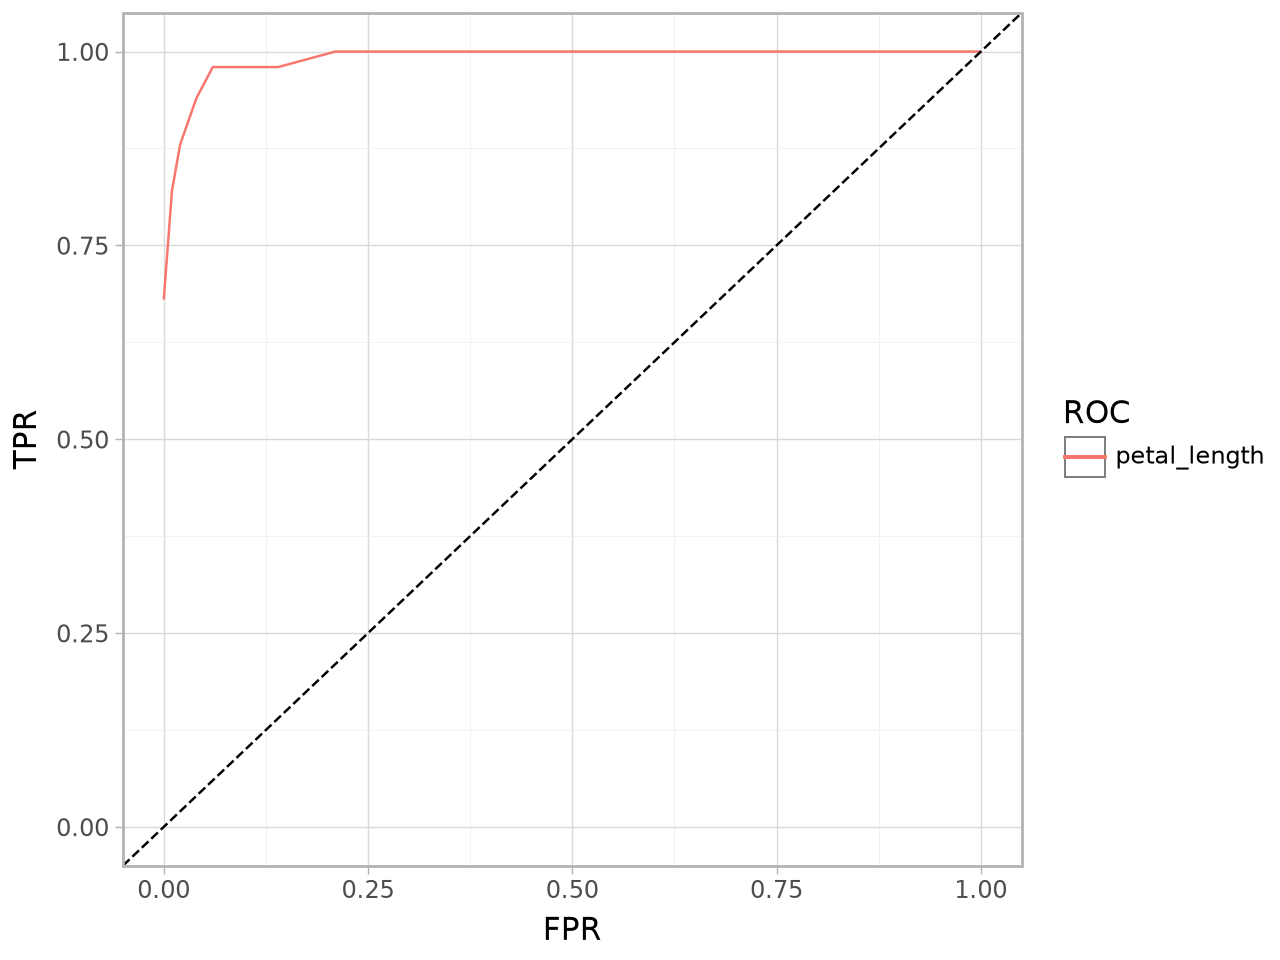

In [29]:
graf_roc(df_petalo, name="petal_length") + theme_light()

**AUC de todas las variables numéricas** del dataset (frente a la clase):

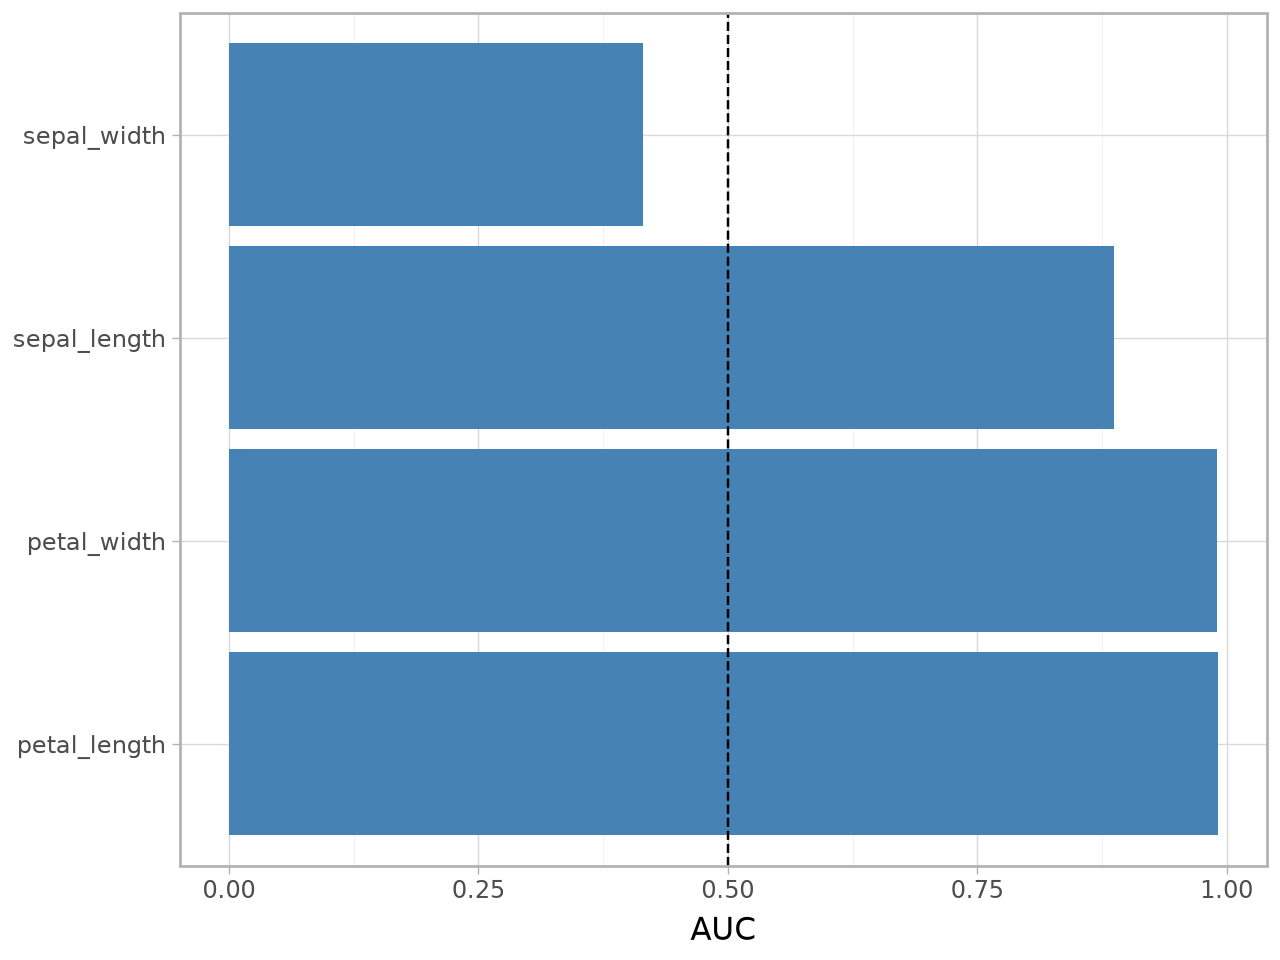

In [30]:
graf_auc(ds) + theme_light()

**Entropía normalizada** de un dataset discretizado:

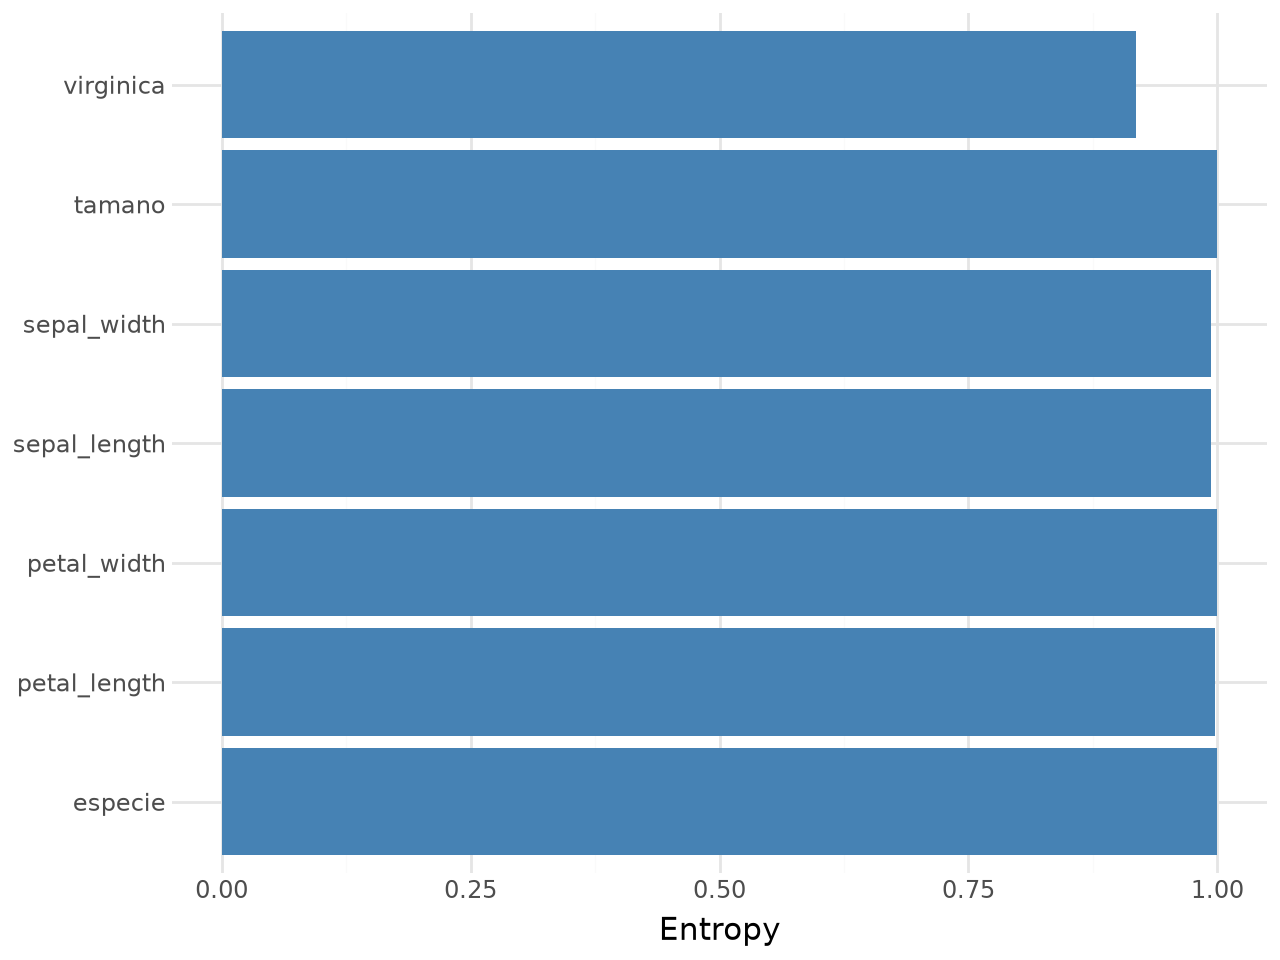

In [31]:
graf_entropia(to_dataframe(ds_disc))

**Matriz de correlaciones** e **información mutua** (`graf_matriz` dibuja cualquier matriz con nombres; `graf_cor` y `graf_mi` son atajos):

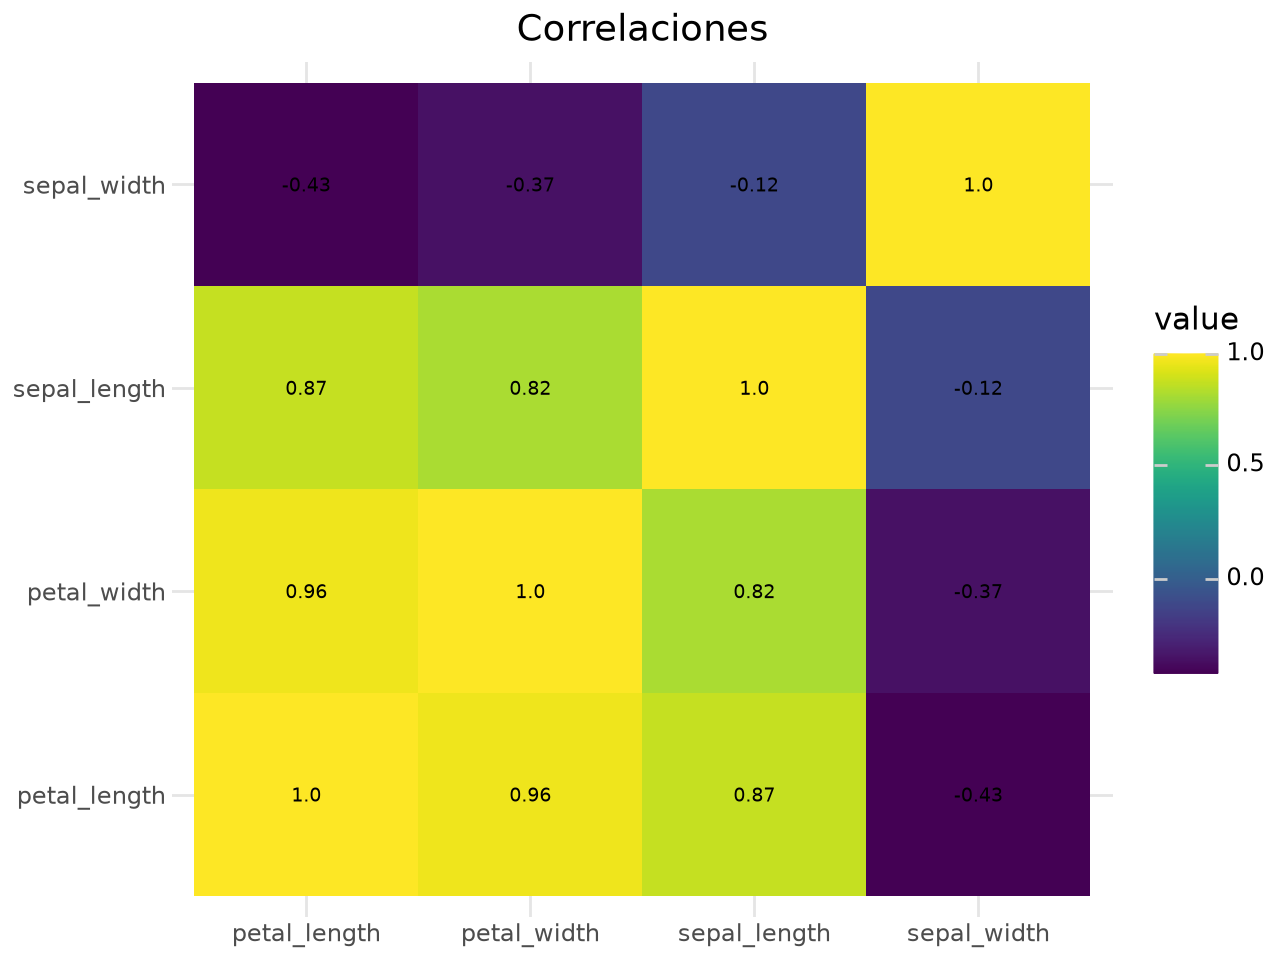

In [32]:
graf_matriz(cor_matrix(ds), "Correlaciones") + theme_minimal()

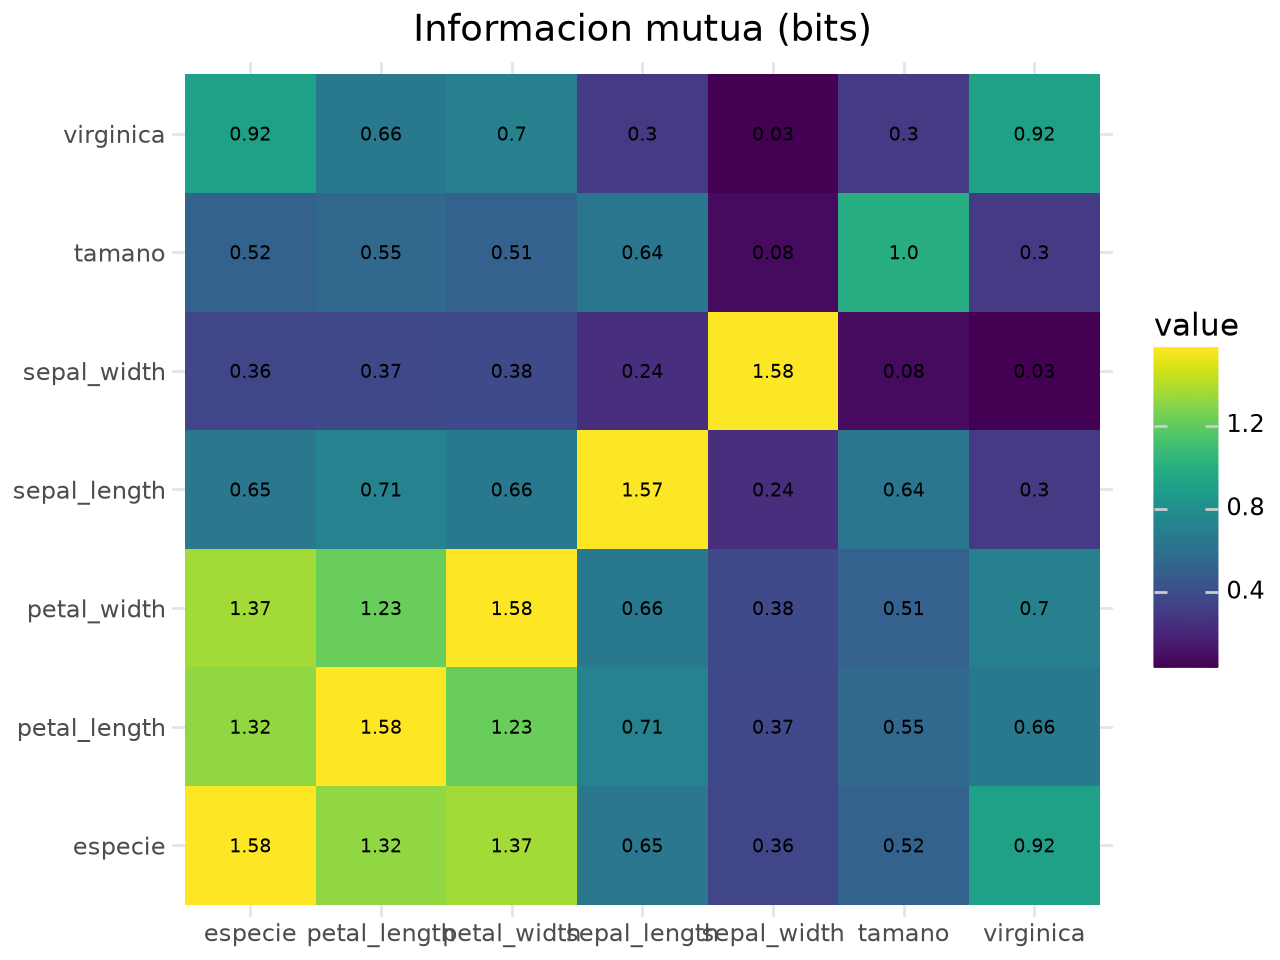

In [33]:
graf_mi(ds, num_bins=3) + theme_minimal()

## 8. Lectura y escritura

In [34]:
import os, tempfile

ruta = os.path.join(tempfile.gettempdir(), "ejemplo.csv")
write_dataset(ds, ruta)

ds2 = read_dataset(ruta, class_name="virginica", max_val=5)
ds2

Dataset: 7 variables
Clase: virginica
 - sepal_length: numeric
 - sepal_width: numeric
 - petal_length: numeric
 - petal_width: numeric
 - especie: categorical
 - tamano: categorical
 - virginica: categorical

## Resumen de funciones

| Tarea | Funciones |
|-------|-----------|
| Objetos | `from_dataframe`, `to_dataframe`, `read_dataset`, `write_dataset` |
| Discretizar | `discretizeEW`, `discretizeEF`, `discretize`, `discretize_dataset`, `discretize_df` |
| Escalar | `normalize`, `standardize`, `normalize_dataset`, `standardize_dataset`, `normalizar_df` |
| Métricas | `entropy`, `rates`, `roc`, `auc`, `auc_variable`, `mutual_info`, `dataset_metrics` |
| Filtrar | `filter_dataset` |
| Asociación | `cor_matrix`, `mi_matrix` |
| Gráficos | `graf_roc`, `graf_auc`, `graf_entropia`, `graf_matriz`, `graf_cor`, `graf_mi` |